# Import Libraries

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Dataset

In [87]:
df = pd.read_csv(r'D:\Self-Project\Data\MEF Dataset\TradewithKeysPartnersCountriesfromJan-Nov2023.csv')

# 1. Inspect Dataset

In [88]:
df.head()

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd
0,World,21292.0,22223.0,43515.0
1,USA,8144.0,223.0,8367.0
2,Japan,1066.0,573.0,1639.0
3,China,1315.0,9763.0,11078.0
4,UK,727.0,74.0,801.0


In [89]:
df.shape

(21, 4)

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   export_destination        21 non-null     str    
 1   export_million_usd        21 non-null     float64
 2   import_million_usd        21 non-null     float64
 3   trade_amount_million_usd  21 non-null     float64
dtypes: float64(3), str(1)
memory usage: 804.0 bytes


In [91]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
export_million_usd,21.0,2284.52381,4757.213624,4.0,325.0,742.0,1315.0,21292.0
import_million_usd,21.0,2418.00000,5285.221282,12.0,61.0,185.0,1403.0,22223.0
trade_amount_million_usd,21.0,4702.52381,9638.972106,26.0,452.0,835.0,4246.0,43515.0


In [92]:
df.describe(include = str).T

,count,unique,top,freq
export_destination,21,21,World,1


`Inspect "export_destination" feature`

In [93]:
df['export_destination'].head()

0    World
1      USA
2    Japan
3    China
4       UK
Name: export_destination, dtype: str

In [94]:
df['export_destination'].str.strip().unique()

<StringArray>
[                'World',                   'USA',                 'Japan',
                 'China',                    'UK',                'Canada',
           'South Korea',             'Australia',                 'India',
           'New Zealand',                 'ASEAN',              'Thailand',
              'Viet Nam',        'European Union',               'Belguim',
                'France',               'Germany',               'Holland',
 'EU and ASEAN Economic',  'United Arab Emirates',                'Others']
Length: 21, dtype: str

### 1st. Key Finding: Identification & Isolation of Aggregate Data
1. **Global Total:** The `'export_destination'` feature contains a `'World'` record representing the combined global trade volume.
2. **Regional Economic Blocs:** Several multi-country aggregate groupings are embedded within the country-level data: `'ASEAN'`, `'European Union'`, and `'EU and ASEAN Economic'`.
3. **Residual Category:** A catch-all record labeled `'Others'` accounts for trade with unlisted or minor trading partners.

- **Solution & Workflow:**
  * Extract and isolate the `'World'` record into a dedicated DataFrame (`world_data`) to preserve the benchmark for market share calculations.
  * Define an exclusion list containing all non-country aggregates:
    ```python
    aggregates = ['World', 'Others', 'ASEAN', 'European Union', 'EU and ASEAN Economic']
    ```
  * Filter out the aggregate entries using boolean negation with `.isin()` (`df[~df['export_destination'].isin(aggregates)]`) to generate a clean, individual-country DataFrame without skewed distributions or double-counted trade flows.

In [95]:
# Isolate 'World' record into a separated df
world_data = df[df['export_destination'] == 'World']

# Isolate 'Others' record into a separated df
other_totals = df[df['export_destination'] == 'Others']

# Isolate 'ASEAN' record into a separated df
asean_data = df[df['export_destination'] == 'ASEAN']

# Isolate 'ASEAN' record into a separated df
european_union_data = df[df['export_destination'] == 'European Union']

# Isolate 'EU and ASEAN Economic' record into a separated df
eu_and_asean_economic_data = df[df['export_destination'] == 'EU and ASEAN Economic']

# Exclude 'World' and 'Others' record from the main df
aggregate = ['World', 'Others', 'ASEAN', 'European Union', 'EU and ASEAN Economic']
df = df[~df['export_destination'].isin(aggregate)]

In [96]:
# Check 'world_data'
world_data.head()

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd
0,World,21292.0,22223.0,43515.0


In [97]:
# Check 'country_data'
df.head()

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd
1,USA,8144.0,223.0,8367.0
2,Japan,1066.0,573.0,1639.0
3,China,1315.0,9763.0,11078.0
4,UK,727.0,74.0,801.0
5,Canada,774.0,61.0,835.0


In [98]:
df.info()

<class 'pandas.DataFrame'>
Index: 16 entries, 1 to 19
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   export_destination        16 non-null     str    
 1   export_million_usd        16 non-null     float64
 2   import_million_usd        16 non-null     float64
 3   trade_amount_million_usd  16 non-null     float64
dtypes: float64(3), str(1)
memory usage: 640.0 bytes


In [99]:
# Check for duplication
df.duplicated().sum()

np.int64(0)

- Looks like our data is cleaned we can now process to do some `feature engineering`

# 2. Feature Engineering

### Calculate `"Trade Balance"`
Calculating the trade balance tells us the actual flow of money between your country and a trading partner, rather than just the total volume of goods moving back and forth.

By subtracting imports from exports (Exports - Imports), we can determine who is coming out ahead financially in the relationship. The result falls into one of two categories:

- **Trade Surplus (Positive Number)**: You sold more goods to that country than you bought from them. Money is flowing into your economy.

- **Trade Deficit (Negative Number)**: You bought more goods from that country than you sold to them. Money is flowing out of your economy to theirs.

In [100]:
# Calculate and create a new column named 'trade_balance'
df['trade_balance'] = df['export_million_usd'] - df['import_million_usd']

In [101]:
# Check the whole dataframe
df

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance
1,USA,8144.0,223.0,8367.0,7921.0
2,Japan,1066.0,573.0,1639.0,493.0
3,China,1315.0,9763.0,11078.0,-8448.0
4,UK,727.0,74.0,801.0,653.0
5,Canada,774.0,61.0,835.0,713.0
6,South Korea,253.0,430.0,683.0,-177.0
7,Australia,325.0,127.0,452.0,198.0
8,India,265.0,179.0,444.0,86.0
9,New Zealand,16.0,22.0,38.0,-6.0
11,Thailand,797.0,2643.0,3440.0,-1846.0


# 3. Data validation
**Definition**: The `trade_amount_million_usd column` represents your Total Trade Volume (or Total Trade Turnover) with that specific country. It tells us how busy or active the relationship is between our country with another country. 
`Note: (export_million_usd + import_million_usd) = trade_amount_million_usd`

Run a quick programmatic check to ensure the `'trade_amount_million_usd'` column is exactly equal to the sum of exports and imports for every records.

In [102]:
validate_df = (df['export_million_usd'] + df['import_million_usd']) == df['trade_amount_million_usd']

validate_df

1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
11    True
12    True
14    True
15    True
16    True
17    True
19    True
dtype: bool

In [103]:
# Valiudate "world" record
validate_world = (world_data['export_million_usd'] + world_data['import_million_usd']) == world_data['trade_amount_million_usd']

validate_world

0    True
dtype: bool

In [104]:
# Validate "Others" record
validate_other = (other_totals['export_million_usd'] + other_totals['import_million_usd']) == other_totals['trade_amount_million_usd']

validate_other

20    True
dtype: bool

- Our data is validated with `no discrepancies`. Now we can move to `EDA`

# 4. Exploratory Data Analysis (EDA)

1. **Top Trade Partners**: Create a bar chart showing our Top 5 countries by Export volume and a separate chart for the Top 5 by Import volume.

In [105]:
# Sort the data in descending order and take the top 5 exports
sorted_export = df.sort_values(by = 'export_million_usd', ascending = False).head(5)

sorted_export

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance
1,USA,8144.0,223.0,8367.0,7921.0
12,Viet Nam,2611.0,3266.0,5877.0,-655.0
3,China,1315.0,9763.0,11078.0,-8448.0
2,Japan,1066.0,573.0,1639.0,493.0
11,Thailand,797.0,2643.0,3440.0,-1846.0


In [106]:
# Sort the data in descending order and take the top 5 imports
sorted_import = df.sort_values(by = 'import_million_usd', ascending = False).head(5)

sorted_import

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance
3,China,1315.0,9763.0,11078.0,-8448.0
12,Viet Nam,2611.0,3266.0,5877.0,-655.0
11,Thailand,797.0,2643.0,3440.0,-1846.0
2,Japan,1066.0,573.0,1639.0,493.0
6,South Korea,253.0,430.0,683.0,-177.0


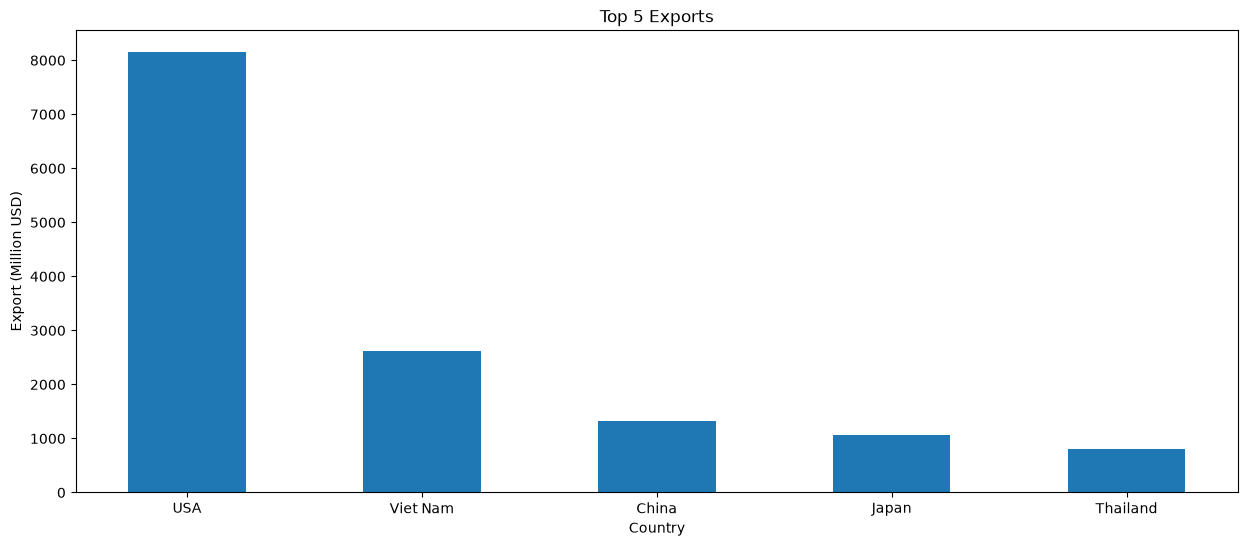

In [107]:
# Top 5 exports chart
plt.figure(figsize = (15, 6))

plt.bar(sorted_export['export_destination'], sorted_export['export_million_usd'], width = 0.5, )
plt.xlabel("Country")
plt.ylabel("Export (Million USD)")
plt.title("Top 5 Exports")
plt.show()

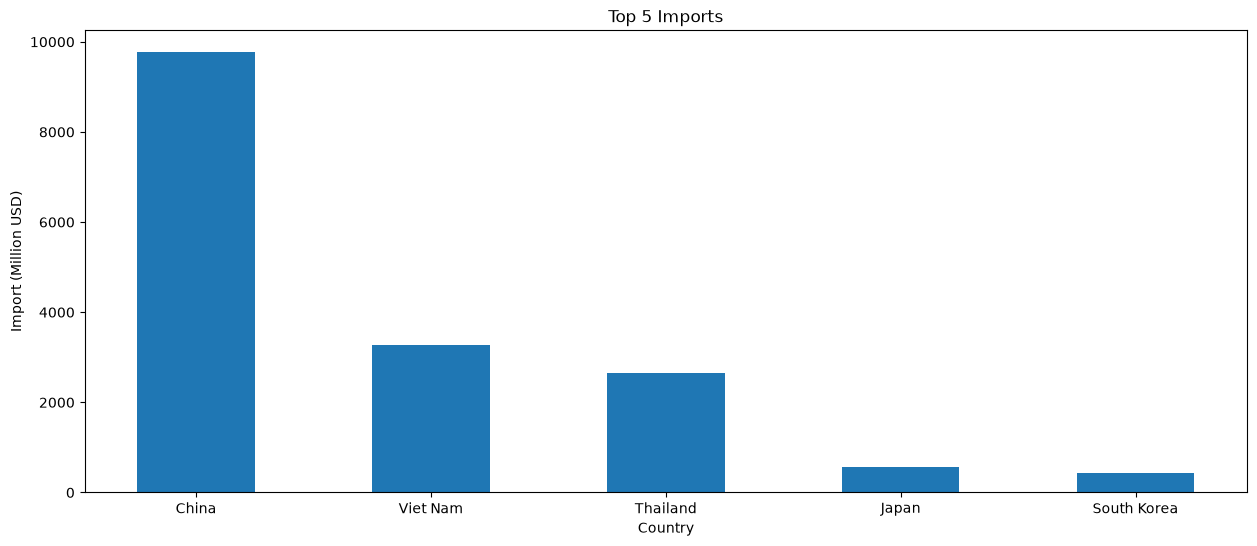

In [108]:
# Top 5 imports chart
plt.figure(figsize = (15, 6))
plt.bar(sorted_import['export_destination'], sorted_import['import_million_usd'], width = 0.5)
plt.xlabel("Country")
plt.ylabel("Import (Million USD)")
plt.title("Top 5 Imports")
plt.show()

2. **Trade Balance Distribution**: Generate a diverging bar chart mapping the Trade_Balance for all individual countries. Apply conditional formatting (e.g., green for surplus, red for deficit) for easy identification.

In [109]:
# Sort the "trade_balance" feature and save it to a new data frame "sorted_trade_balance"
sorted_trade_balance = df.sort_values(by = 'trade_balance', ascending = False)

sorted_trade_balance

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance
1,USA,8144.0,223.0,8367.0,7921.0
5,Canada,774.0,61.0,835.0,713.0
4,UK,727.0,74.0,801.0,653.0
16,Germany,742.0,185.0,927.0,557.0
2,Japan,1066.0,573.0,1639.0,493.0
17,Holland,509.0,40.0,549.0,469.0
14,Belguim,398.0,51.0,449.0,347.0
7,Australia,325.0,127.0,452.0,198.0
15,France,333.0,147.0,480.0,186.0
8,India,265.0,179.0,444.0,86.0


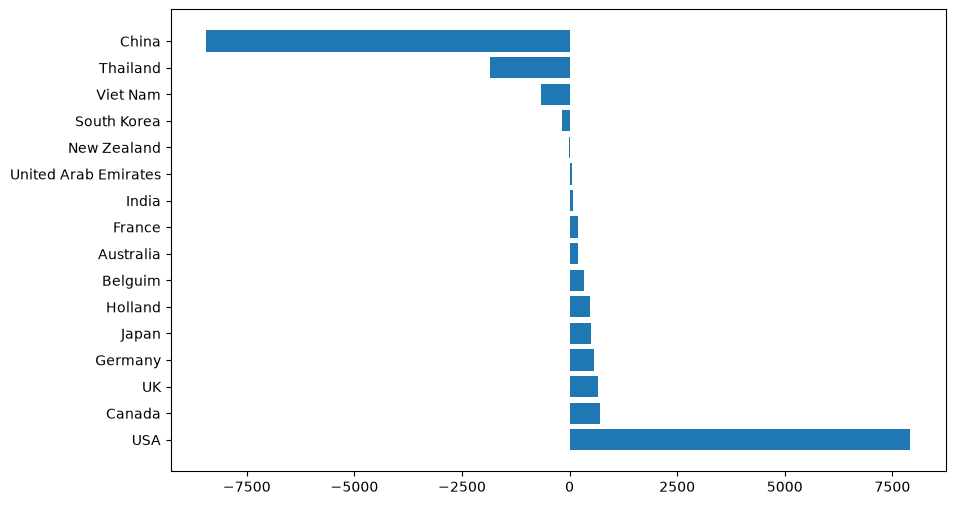

In [110]:
# Build a horizontal bar chart
plt.figure(figsize = (10, 6))

plt.barh(sorted_trade_balance['export_destination'], sorted_trade_balance['trade_balance'])
plt.show()

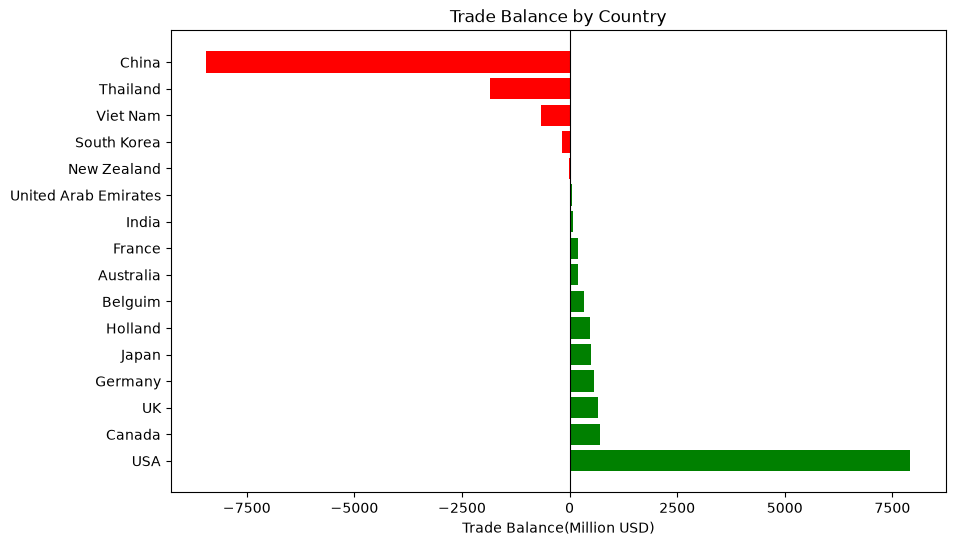

In [111]:
# Build a horizontal bar chart with colors
# Green = surplus (positive)
# Red = deficit (negative)

# Store colors
colors = []

# Filter with colors
for balance in sorted_trade_balance['trade_balance']:
    if balance > 0: # Surplus
        colors.append('green')
    else: # Deficit
        colors.append('red')

# Create horizontal bar chart
plt.figure(figsize = (10, 6))
plt.barh(sorted_trade_balance['export_destination'], sorted_trade_balance['trade_balance'], color = colors)

plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Trade Balance(Million USD)')
plt.title('Trade Balance by Country')
plt.show()

3. **Market Share**: I'll use the `'World'` record I isolated earlier, to calculate the percentage of total global exports that go to our top 3 individual partners. Then display this as a brief summary table.

In [112]:
# Sort the 'trade_amount_million_usd' feature for the top 3 global individual partners
top_3_partners = df.sort_values(by = 'trade_amount_million_usd', ascending = False).head(3)

top_3_partners

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance
3,China,1315.0,9763.0,11078.0,-8448.0
1,USA,8144.0,223.0,8367.0,7921.0
12,Viet Nam,2611.0,3266.0,5877.0,-655.0


In [113]:
# Extract the trade amount from the world record we've isolated.
world_trade_amount = world_data['trade_amount_million_usd'].values[0]

world_trade_amount

np.float64(43515.0)

In [115]:
# Calculate top 3 partners market share percentage
top_3_partners['market_share_pct'] = (top_3_partners['trade_amount_million_usd'] / world_trade_amount) * 100

top_3_partners['market_share_pct']

3     25.457888
1     19.227852
12    13.505688
Name: market_share_pct, dtype: float64

In [116]:
top_3_partners

,export_destination,export_million_usd,import_million_usd,trade_amount_million_usd,trade_balance,market_share_pct
3,China,1315.0,9763.0,11078.0,-8448.0,25.457888
1,USA,8144.0,223.0,8367.0,7921.0,19.227852
12,Viet Nam,2611.0,3266.0,5877.0,-655.0,13.505688


### Key Takeaway
- From January to November 2023, Cambodia's global trade heavily relied on `three primary partner` nations, which collectively accounted for over `58% of the country's total international trade volume`. `China` represented the largest overall trading relationship `(25.46% market share)`, driven predominantly by high import volumes that resulted in a trade deficit of `$8,448 million`. In contrast, the `United States (19.23% market share)` served as the primary engine for export earnings, single-handedly generating a robust trade surplus of `$7,921 million`. `Vietnam (13.51% market share)` rounded out the top three as a balanced, high-volume regional partner with a moderate deficit of `$655 million`.